<a href="https://colab.research.google.com/github/tahzibultamim/PythonProjects/blob/sM/iee.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected successfully!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected successfully!


In [2]:
!pip install -q shap xgboost

In [3]:

# ==========================================
# CELL 1: INSTALL ALL REQUIRED PACKAGES
# ==========================================

%pip install -q numpy pandas matplotlib seaborn scikit-learn xgboost shap joblib

print("All research packages installed successfully!")


All research packages installed successfully!


In [4]:

# ==========================================
# CELL 2: IMPORT LIBRARIES
# ==========================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import xgboost
import sklearn
import joblib

from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, VarianceThreshold

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from xgboost import XGBClassifier

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    confusion_matrix
)

warnings.filterwarnings("ignore")

SEED = 42

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("SHAP:", shap.__version__)

print("\nAll libraries imported successfully!")


NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
XGBoost: 3.4.1
SHAP: 0.54.1

All libraries imported successfully!


In [8]:
# ==========================================
# CELL 4: LOAD TCGA-THCA DATASET
# ==========================================
import os
from pathlib import Path
import pandas as pd

# The file was found in the 'datasets' (plural) folder in Google Drive
DATA_PATH = "/content/drive/MyDrive/datasets/TCGA_THCA_FINAL_DATASET.csv"
RESULTS_DIR = Path("/content/drive/MyDrive/datasets/TCGA_THCA_Research_Results")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        f"Please verify the path or the folder structure in your Google Drive."
    )

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (517, 19967)


,sample_submitter_id,file_id,patient_id,sample_type,label,ENSG00000000003.15__TSPAN6,ENSG00000000005.6__TNMD,ENSG00000000419.13__DPM1,ENSG00000000457.14__SCYL3,ENSG00000000460.17__C1orf112,...,ENSG00000288649.1__ACTL10,ENSG00000288654.1__AC119733.1,ENSG00000288656.1__AC020765.6,ENSG00000288658.1__AC010980.1,ENSG00000288660.1__AC004233.4,ENSG00000288661.1__AL451106.1,ENSG00000288669.1__AC008763.4,ENSG00000288671.1__AC006486.3,ENSG00000288674.1__AL391628.1,ENSG00000288675.1__AP006621.6
0,TCGA-4C-A93U-01A,d7082abc-9812-4d52-a61f-3d0c005e5ade,TCGA-4C-A93U,Primary Tumor,1,5.64094,0.685088,6.18679,2.79967,1.87468,...,0,0,0.00000,0.264957,0.000000,0,0.0,0,0.097476,0.848798
1,TCGA-BJ-A0Z3-01A,b78a76b0-0be6-4f47-ae53-7b4a6b339888,TCGA-BJ-A0Z3,Primary Tumor,1,5.74985,0.000000,6.29341,3.18552,1.80876,...,0,0,0.00000,0.175301,0.233520,0,0.0,0,0.080658,1.097950
2,TCGA-BJ-A0ZC-01A,07c4db33-2a66-40be-b5fb-3c9b3271b874,TCGA-BJ-A0ZC,Primary Tumor,1,5.39993,0.267596,6.34008,3.50024,1.22373,...,0,0,0.00000,3.053270,0.000000,0,0.0,0,0.022332,0.488412
3,TCGA-BJ-A18Y-01A,4b73aa55-1b96-4d6a-afef-fae80dc44ffe,TCGA-BJ-A18Y,Primary Tumor,1,5.35339,0.128293,6.50881,3.34527,1.37095,...,0,0,0.04991,1.463570,0.000000,0,0.0,0,0.080112,1.015280
4,TCGA-BJ-A18Z-01A,d3572a69-92b7-4696-8894-d52ababe370d,TCGA-BJ-A18Z,Primary Tumor,1,5.42082,0.000000,6.17039,2.89569,1.64902,...,0,0,0.00000,0.483880,0.158596,0,0.0,0,0.061983,1.237200


In [9]:

# ==========================================
# CELL 5: DATA QUALITY CHECK
# ==========================================

metadata_cols = [
    "sample_submitter_id",
    "file_id",
    "patient_id",
    "sample_type",
    "label"
]

required = metadata_cols

missing_columns = [
    col for col in required if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

gene_cols = [
    col for col in df.columns
    if col not in metadata_cols
]

X = df[gene_cols].apply(
    pd.to_numeric,
    errors="coerce"
).astype(np.float32)

y = df["label"].astype(int)

groups = df["patient_id"].astype(str)

expected_labels = df["sample_type"].map({
    "Primary Tumor": 1,
    "Solid Tissue Normal": 0
})

assert expected_labels.notna().all()
assert np.array_equal(
    expected_labels.to_numpy(),
    y.to_numpy()
)

assert df["patient_id"].notna().all()
assert df["sample_submitter_id"].is_unique
assert X.isna().sum().sum() == 0
assert np.isfinite(X.to_numpy()).all()

print("Samples:", X.shape[0])
print("Genes:", X.shape[1])
print("Unique patients:", groups.nunique())

print("\nSample distribution:")
print(df["sample_type"].value_counts())

print("\nClass distribution:")
print(y.value_counts())

print("\nMissing values:", X.isna().sum().sum())
print("Infinite values:", np.isinf(X.to_numpy()).sum())

print("\nDATA QUALITY VERIFIED!")


Samples: 517
Genes: 19962
Unique patients: 462

Sample distribution:
sample_type
Primary Tumor          458
Solid Tissue Normal     59
Name: count, dtype: int64

Class distribution:
label
1    458
0     59
Name: count, dtype: int64

Missing values: 0
Infinite values: 0

DATA QUALITY VERIFIED!


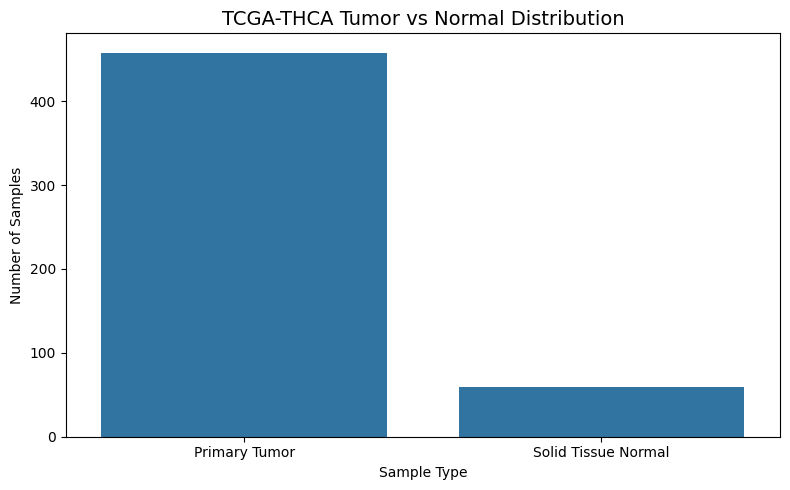

In [10]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sample_type"
)

plt.title(
    "TCGA-THCA Tumor vs Normal Distribution",
    fontsize=14
)

plt.xlabel("Sample Type")
plt.ylabel("Number of Samples")

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "01_sample_distribution.png",
    dpi=300
)

plt.show()


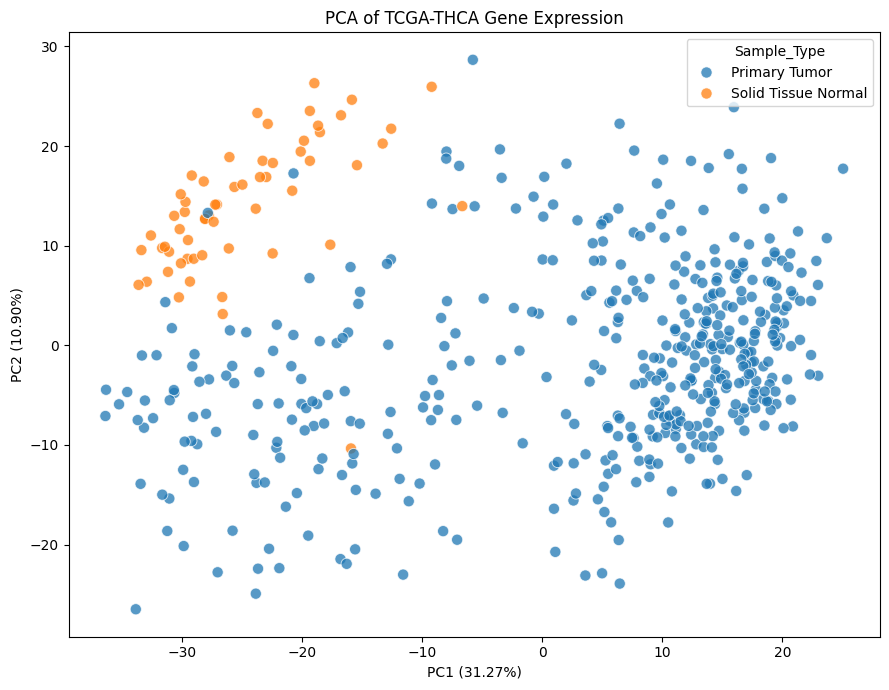

In [11]:

from sklearn.decomposition import PCA

# Select 1000 most variable genes
gene_variance = X.var(axis=0)

top_genes = gene_variance.nlargest(1000).index

X_pca = X[top_genes]

# Standardization for visualization
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_pca)

# PCA
pca = PCA(n_components=2)

coordinates = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    coordinates,
    columns=["PC1", "PC2"]
)

pca_df["Sample_Type"] = df["sample_type"].values

# Plot
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Sample_Type",
    s=65,
    alpha=0.75
)

plt.title("PCA of TCGA-THCA Gene Expression")

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)"
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "02_PCA_plot.png",
    dpi=300
)

plt.show()


In [12]:

# ==========================================
# CELL 8: FEATURE SELECTION + MODELS
# ==========================================

K_FEATURES = 500

def create_pipeline(model, scale=False):

    steps = [
        ("variance", VarianceThreshold()),
        ("select", SelectKBest(
            score_func=f_classif,
            k=K_FEATURES
        ))
    ]

    if scale:
        steps.append(
            ("scaler", StandardScaler())
        )

    steps.append(
        ("model", model)
    )

    return Pipeline(steps)


models = {

    "Logistic Regression": create_pipeline(
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=SEED
        ),
        scale=True
    ),

    "Decision Tree": create_pipeline(
        DecisionTreeClassifier(
            max_depth=4,
            class_weight="balanced",
            random_state=SEED
        )
    ),

    "Random Forest": create_pipeline(
        RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced_subsample",
            random_state=SEED,
            n_jobs=-1
        )
    ),

    "Gradient Boosting": create_pipeline(
        GradientBoostingClassifier(
            random_state=SEED
        )
    ),

    "XGBoost": create_pipeline(
        XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=SEED,
            n_jobs=-1
        )
    ),

    "SVM": create_pipeline(
        SVC(
            probability=False,
            class_weight="balanced",
            random_state=SEED
        ),
        scale=True
    ),

    "KNN": create_pipeline(
        KNeighborsClassifier(
            n_neighbors=5,
            weights="distance"
        ),
        scale=True
    )
}

print("Total models:", len(models))

for name in models:
    print(" -", name)


Total models: 7
 - Logistic Regression
 - Decision Tree
 - Random Forest
 - Gradient Boosting
 - XGBoost
 - SVM
 - KNN


In [13]:

# ==========================================
# CELL 9: STRATIFIED GROUP CROSS-VALIDATION
# ==========================================

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

splits = list(
    cv.split(X, y, groups)
)

for fold, (train_idx, test_idx) in enumerate(
    splits, 1
):

    train_patients = set(groups.iloc[train_idx])
    test_patients = set(groups.iloc[test_idx])

    assert train_patients.isdisjoint(
        test_patients
    )

    print(f"\nFOLD {fold}")

    print("Training samples:", len(train_idx))
    print("Validation samples:", len(test_idx))

    print(
        "Training labels:",
        y.iloc[train_idx].value_counts().to_dict()
    )

    print(
        "Validation labels:",
        y.iloc[test_idx].value_counts().to_dict()
    )

    if y.iloc[test_idx].nunique() != 2:
        raise ValueError(
            f"Fold {fold} does not contain both classes."
        )

print("\nPatient-level cross-validation verified!")



FOLD 1
Training samples: 413
Validation samples: 104
Training labels: {1: 366, 0: 47}
Validation labels: {1: 92, 0: 12}

FOLD 2
Training samples: 414
Validation samples: 103
Training labels: {1: 366, 0: 48}
Validation labels: {1: 92, 0: 11}

FOLD 3
Training samples: 414
Validation samples: 103
Training labels: {1: 367, 0: 47}
Validation labels: {1: 91, 0: 12}

FOLD 4
Training samples: 412
Validation samples: 105
Training labels: {1: 366, 0: 46}
Validation labels: {1: 92, 0: 13}

FOLD 5
Training samples: 415
Validation samples: 102
Training labels: {1: 367, 0: 48}
Validation labels: {1: 91, 0: 11}

Patient-level cross-validation verified!


In [14]:

# ==========================================
# CELL 10: TRAIN AND EVALUATE SEVEN MODELS
# ==========================================

results = []

for model_name, model in models.items():

    print("\n================================")
    print("TRAINING:", model_name)
    print("================================")

    for fold, (train_idx, test_idx) in enumerate(
        splits, 1
    ):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        fitted_model = clone(model)

        fit_kwargs = {}

        # Class balancing for boosting models
        if model_name in [
            "Gradient Boosting",
            "XGBoost"
        ]:

            weights = compute_sample_weight(
                class_weight="balanced",
                y=y_train
            )

            fit_kwargs["model__sample_weight"] = weights

        # Train
        fitted_model.fit(
            X_train,
            y_train,
            **fit_kwargs
        )

        # Predictions
        predictions = fitted_model.predict(X_test)

        # Ranking scores
        if hasattr(fitted_model, "predict_proba"):

            positive_scores = (
                fitted_model.predict_proba(X_test)[:, 1]
            )

            negative_scores = 1 - positive_scores

        else:

            positive_scores = (
                fitted_model.decision_function(X_test)
            )

            negative_scores = -positive_scores

        # Confusion matrix
        tn, fp, fn, tp = confusion_matrix(
            y_test,
            predictions,
            labels=[0, 1]
        ).ravel()

        sensitivity = (
            tp / (tp + fn)
            if (tp + fn) else 0
        )

        specificity = (
            tn / (tn + fp)
            if (tn + fp) else 0
        )

        # Metrics
        fold_result = {

            "Model": model_name,

            "Fold": fold,

            "Accuracy": accuracy_score(
                y_test, predictions
            ),

            "Balanced_Accuracy": balanced_accuracy_score(
                y_test, predictions
            ),

            "Precision_Tumor": precision_score(
                y_test,
                predictions,
                zero_division=0
            ),

            "Sensitivity_Tumor": sensitivity,

            "Specificity_Normal": specificity,

            "F1_Tumor": f1_score(
                y_test,
                predictions,
                zero_division=0
            ),

            "ROC_AUC": roc_auc_score(
                y_test,
                positive_scores
            ),

            "PR_AUC_Tumor": average_precision_score(
                y_test,
                positive_scores
            ),

            "PR_AUC_Normal": average_precision_score(
                1 - y_test,
                negative_scores
            ),

            "MCC": matthews_corrcoef(
                y_test,
                predictions
            )
        }

        results.append(fold_result)

        print(
            f"Fold {fold}: "
            f"ROC-AUC={fold_result['ROC_AUC']:.4f}, "
            f"MCC={fold_result['MCC']:.4f}"
        )

    print("Completed:", model_name)

results_df = pd.DataFrame(results)

print("\nALL MODELS COMPLETED!")

display(results_df.head())



TRAINING: Logistic Regression
Fold 1: ROC-AUC=0.9683, MCC=0.8275
Fold 2: ROC-AUC=1.0000, MCC=0.9098
Fold 3: ROC-AUC=0.9945, MCC=0.9156
Fold 4: ROC-AUC=1.0000, MCC=1.0000
Fold 5: ROC-AUC=1.0000, MCC=0.9097
Completed: Logistic Regression

TRAINING: Decision Tree
Fold 1: ROC-AUC=0.9167, MCC=0.9031
Fold 2: ROC-AUC=0.9946, MCC=0.9522
Fold 3: ROC-AUC=0.9167, MCC=0.9030
Fold 4: ROC-AUC=0.9231, MCC=0.9100
Fold 5: ROC-AUC=0.8926, MCC=0.7560
Completed: Decision Tree

TRAINING: Random Forest
Fold 1: ROC-AUC=0.9792, MCC=0.9058
Fold 2: ROC-AUC=1.0000, MCC=0.9522
Fold 3: ROC-AUC=1.0000, MCC=0.9522
Fold 4: ROC-AUC=1.0000, MCC=0.8631
Fold 5: ROC-AUC=1.0000, MCC=1.0000
Completed: Random Forest

TRAINING: Gradient Boosting
Fold 1: ROC-AUC=0.9529, MCC=0.9058
Fold 2: ROC-AUC=0.9926, MCC=0.9522
Fold 3: ROC-AUC=0.9973, MCC=0.9522
Fold 4: ROC-AUC=0.9615, MCC=0.9100
Fold 5: ROC-AUC=0.8242, MCC=0.8420
Completed: Gradient Boosting

TRAINING: XGBoost
Fold 1: ROC-AUC=0.9828, MCC=0.8645
Fold 2: ROC-AUC=1.0000, MC

,Model,Fold,Accuracy,Balanced_Accuracy,Precision_Tumor,Sensitivity_Tumor,Specificity_Normal,F1_Tumor,ROC_AUC,PR_AUC_Tumor,PR_AUC_Normal,MCC
0,Logistic Regression,1,0.961538,0.942029,0.988889,0.967391,0.916667,0.978022,0.968297,0.995574,0.810093,0.827523
1,Logistic Regression,2,0.980583,0.989130,1.000000,0.978261,1.000000,0.989011,1.000000,1.000000,1.000000,0.909813
2,Logistic Regression,3,0.980583,0.989011,1.000000,0.978022,1.000000,0.988889,0.994505,0.999298,0.959366,0.915590
3,Logistic Regression,4,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
4,Logistic Regression,5,0.980392,0.989011,1.000000,0.978022,1.000000,0.988889,1.000000,1.000000,1.000000,0.909702


In [15]:

# ==========================================
# CELL 11: MODEL PERFORMANCE SUMMARY
# ==========================================

metric_columns = [
    "Accuracy",
    "Balanced_Accuracy",
    "Precision_Tumor",
    "Sensitivity_Tumor",
    "Specificity_Normal",
    "F1_Tumor",
    "ROC_AUC",
    "PR_AUC_Tumor",
    "PR_AUC_Normal",
    "MCC"
]

summary = results_df.groupby("Model")[
    metric_columns
].agg(["mean", "std"])

summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in summary.columns
]

summary = summary.sort_values(
    "MCC_mean",
    ascending=False
)

display(summary.round(4))

# Save results to Google Drive
results_df.to_csv(
    RESULTS_DIR / "Seven_Model_Fold_Results.csv",
    index=False
)

summary.to_csv(
    RESULTS_DIR / "Seven_Model_Performance_Summary.csv"
)

print("Performance results saved!")


,Accuracy_mean,Accuracy_std,Balanced_Accuracy_mean,Balanced_Accuracy_std,Precision_Tumor_mean,Precision_Tumor_std,Sensitivity_Tumor_mean,Sensitivity_Tumor_std,Specificity_Normal_mean,Specificity_Normal_std,F1_Tumor_mean,F1_Tumor_std,ROC_AUC_mean,ROC_AUC_std,PR_AUC_Tumor_mean,PR_AUC_Tumor_std,PR_AUC_Normal_mean,PR_AUC_Normal_std,MCC_mean,MCC_std
Model,,,,,,,,,,,,,,,,,,,,
XGBoost,0.9884,0.0105,0.9724,0.0234,0.9935,0.0060,0.9935,0.0097,0.9513,0.0446,0.9935,0.0060,0.9966,0.0077,0.9995,0.0011,0.9877,0.0276,0.9449,0.0493
KNN,0.9865,0.0086,0.9719,0.0329,0.9936,0.0095,0.9913,0.0092,0.9526,0.0696,0.9924,0.0049,0.9735,0.0354,0.9930,0.0096,0.9237,0.0753,0.9355,0.0407
Random Forest,0.9866,0.0109,0.9581,0.0461,0.9893,0.0129,0.9957,0.0060,0.9205,0.0943,0.9924,0.0061,0.9958,0.0093,0.9994,0.0014,0.9846,0.0343,0.9347,0.0521
SVM,0.9826,0.0143,0.9697,0.0348,0.9935,0.0096,0.9869,0.0142,0.9526,0.0696,0.9901,0.0082,0.9949,0.0108,0.9993,0.0015,0.9707,0.0624,0.9199,0.0636
Logistic Regression,0.9806,0.0136,0.9818,0.0228,0.9978,0.0050,0.9803,0.0119,0.9833,0.0373,0.9890,0.0078,0.9926,0.0138,0.9990,0.0019,0.9539,0.0823,0.9125,0.0610
Gradient Boosting,0.9826,0.0082,0.9465,0.0349,0.9870,0.0090,0.9935,0.0060,0.8995,0.0710,0.9902,0.0046,0.9457,0.0706,0.9872,0.0159,0.9101,0.0542,0.9124,0.0452
Decision Tree,0.9767,0.0150,0.9287,0.0386,0.9827,0.0097,0.9912,0.0143,0.8662,0.0754,0.9869,0.0084,0.9287,0.0386,0.9819,0.0096,0.8241,0.1099,0.8849,0.0749


Performance results saved!


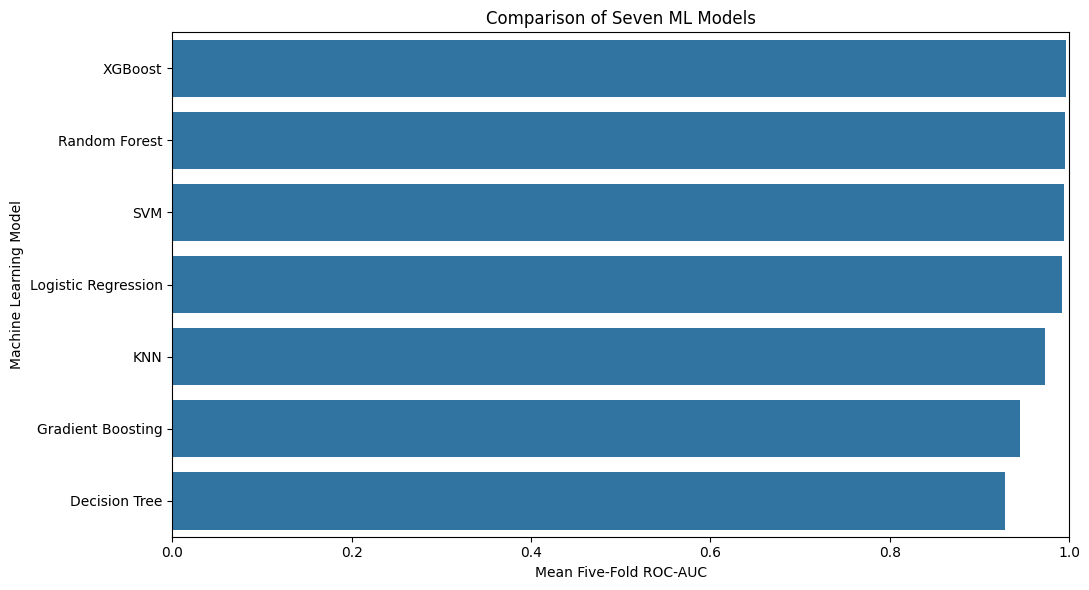

In [16]:

plt.figure(figsize=(11, 6))

plot_df = (
    results_df.groupby("Model")["ROC_AUC"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

sns.barplot(
    data=plot_df,
    x="ROC_AUC",
    y="Model"
)

plt.title("Comparison of Seven ML Models")
plt.xlabel("Mean Five-Fold ROC-AUC")
plt.ylabel("Machine Learning Model")

plt.xlim(0, 1)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "03_Model_Comparison_ROC_AUC.png",
    dpi=300
)

plt.show()


In [17]:

# ==========================================
# CELL 12: SHAP INITIALIZATION
# ==========================================

import shap

print("SHAP version:", shap.__version__)

tree_models = [
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting",
    "XGBoost"
]

# Select the best tree model based on mean CV MCC
best_tree_model = summary.loc[
    tree_models,
    "MCC_mean"
].idxmax()

print("Best tree-based model:", best_tree_model)

print(
    "Mean MCC:",
    round(
        summary.loc[best_tree_model, "MCC_mean"],
        4
    )
)


SHAP version: 0.54.1
Best tree-based model: XGBoost
Mean MCC: 0.9449


In [18]:

# ==========================================
# CELL 13: TRAIN SELECTED TREE MODEL
# ==========================================

train_idx, test_idx = splits[0]

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

shap_model = clone(
    models[best_tree_model]
)

fit_kwargs = {}

if best_tree_model in [
    "Gradient Boosting",
    "XGBoost"
]:

    weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train
    )

    fit_kwargs["model__sample_weight"] = weights

shap_model.fit(
    X_train,
    y_train,
    **fit_kwargs
)

print("SHAP model trained successfully!")

print(
    "Training patients:",
    groups.iloc[train_idx].nunique()
)

print(
    "Held-out patients:",
    groups.iloc[test_idx].nunique()
)


SHAP model trained successfully!
Training patients: 369
Held-out patients: 93


In [19]:

# ==========================================
# CELL 14: EXTRACT SELECTED GENES
# ==========================================

# Apply fitted preprocessing to held-out data
X_test_transformed = shap_model[:-1].transform(
    X_test
)

# Recover the original gene names
variance_mask = (
    shap_model.named_steps["variance"]
    .get_support()
)

genes_after_variance = X.columns[
    variance_mask
]

selection_mask = (
    shap_model.named_steps["select"]
    .get_support()
)

selected_gene_names = genes_after_variance[
    selection_mask
]

X_test_selected = pd.DataFrame(
    X_test_transformed,
    columns=selected_gene_names
)

print(
    "Selected genes:",
    len(selected_gene_names)
)

print(
    "SHAP input shape:",
    X_test_selected.shape
)

display(
    X_test_selected.iloc[:5, :10]
)


Selected genes: 500
SHAP input shape: (104, 500)


,ENSG00000003436.16__TFPI,ENSG00000004399.13__PLXND1,ENSG00000004776.13__HSPB6,ENSG00000006625.18__GGCT,ENSG00000007062.12__PROM1,ENSG00000008256.16__CYTH3,ENSG00000008277.14__ADAM22,ENSG00000009694.13__TENM1,ENSG00000012223.13__LTF,ENSG00000015475.19__BID
0,2.350550,6.16224,1.977870,6.64343,0.531469,5.00117,1.089090,3.217340,6.51582,5.26943
1,0.714136,5.95462,0.231555,4.44975,0.264476,5.30182,3.387620,0.783666,6.61806,3.90574
2,2.680120,4.69024,2.160440,4.79704,0.436162,3.89495,1.316730,0.205518,7.26770,4.26457
3,0.861161,4.78010,0.631058,4.98609,0.020200,3.33143,0.977683,1.386090,4.18835,3.45929
4,3.434370,4.81491,1.442010,4.09463,3.522010,6.18257,2.352080,1.975340,4.20282,3.22994


In [20]:

# ==========================================
# CELL 15: CALCULATE SHAP VALUES
# ==========================================

tree_classifier = shap_model.named_steps["model"]

explainer = shap.TreeExplainer(
    tree_classifier
)

shap_explanation = explainer(
    X_test_selected,
    check_additivity=False
)

shap_values = shap_explanation.values

# Handle binary classifier output
if isinstance(shap_values, list):

    shap_values = shap_values[1]

elif shap_values.ndim == 3:

    shap_values = shap_values[:, :, 1]

print("SHAP calculation completed!")

print("SHAP values shape:", shap_values.shape)


SHAP calculation completed!
SHAP values shape: (104, 500)


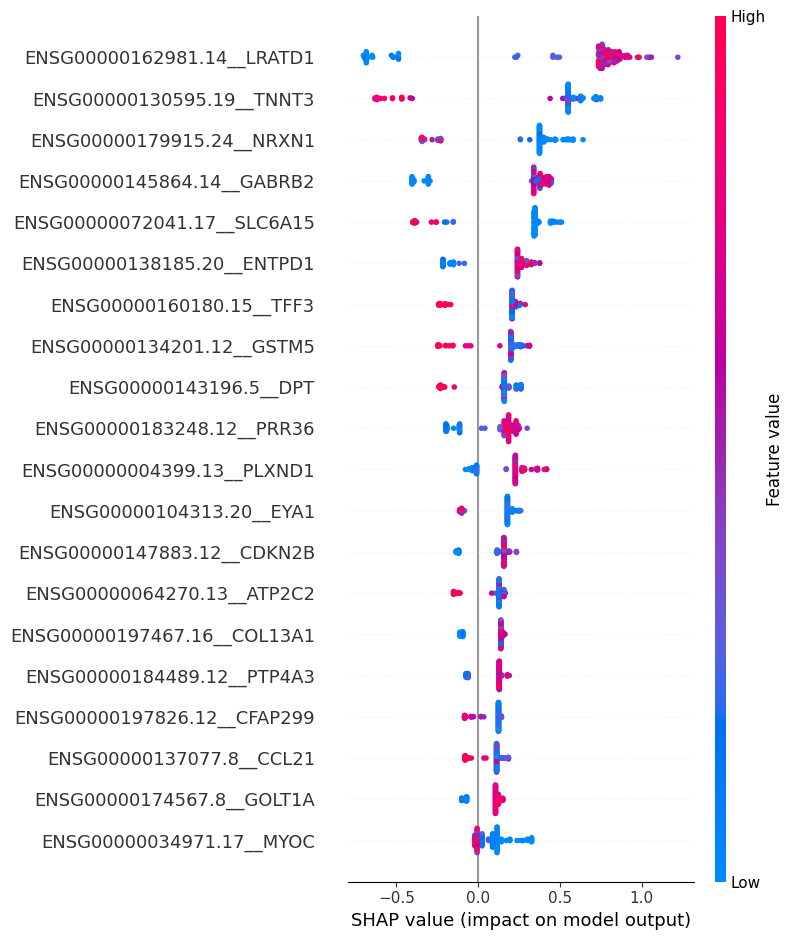

In [21]:

# ==========================================
# CELL 16: SHAP SUMMARY PLOT
# ==========================================

shap.summary_plot(
    shap_values,
    X_test_selected,
    max_display=20,
    show=False
)

plt.savefig(
    RESULTS_DIR / "04_SHAP_Summary_Plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


,Gene,Mean_Absolute_SHAP
283,ENSG00000162981.14__LRATD1,0.749323
143,ENSG00000130595.19__TNNT3,0.578644
389,ENSG00000179915.24__NRXN1,0.383707
202,ENSG00000145864.14__GABRB2,0.374605
33,ENSG00000072041.17__SLC6A15,0.357878
172,ENSG00000138185.20__ENTPD1,0.247438
266,ENSG00000160180.15__TFF3,0.216769
157,ENSG00000134201.12__GSTM5,0.210168
190,ENSG00000143196.5__DPT,0.186173
396,ENSG00000183248.12__PRR36,0.185860


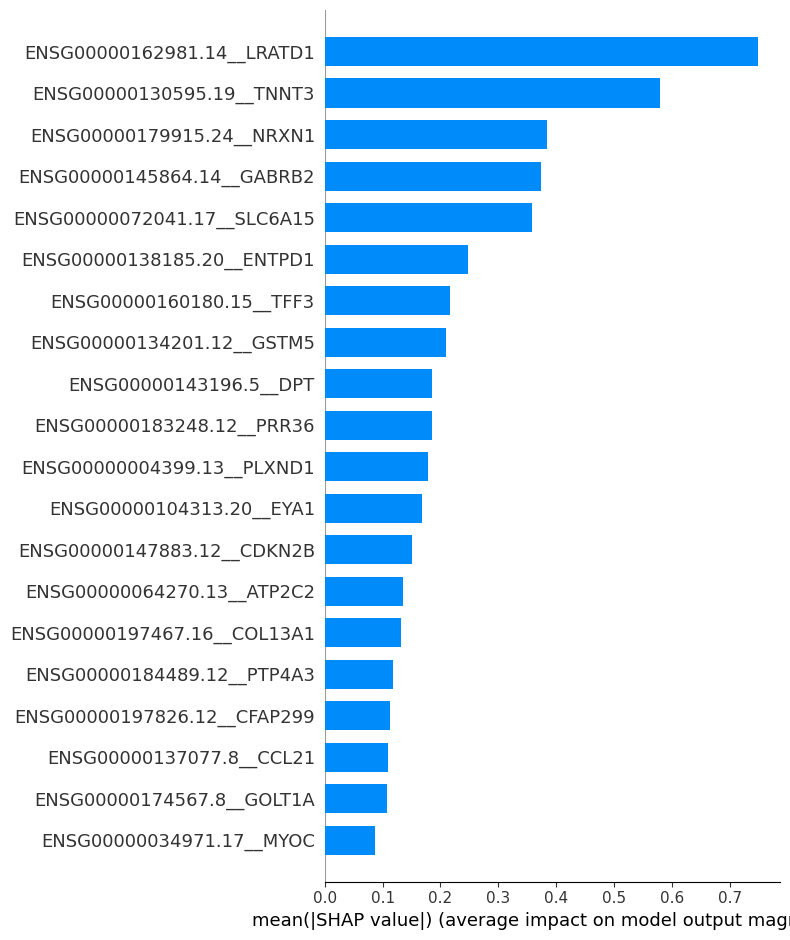

In [22]:

# ==========================================
# CELL 17: SHAP FEATURE IMPORTANCE
# ==========================================

shap_importance = pd.DataFrame({

    "Gene": selected_gene_names,

    "Mean_Absolute_SHAP": np.abs(
        shap_values
    ).mean(axis=0)

})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

display(
    shap_importance.head(20)
)

shap_importance.to_csv(
    RESULTS_DIR / "SHAP_Gene_Importance.csv",
    index=False
)

# Bar plot
shap.summary_plot(
    shap_values,
    X_test_selected,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.savefig(
    RESULTS_DIR / "05_SHAP_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Most important gene: ENSG00000162981.14__LRATD1


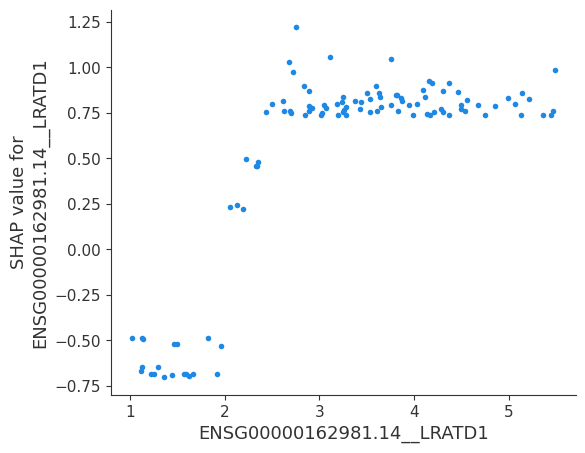

In [23]:

# ==========================================
# CELL 18: SHAP DEPENDENCE PLOT
# ==========================================

top_gene = shap_importance.iloc[0]["Gene"]

print("Most important gene:", top_gene)

shap.dependence_plot(
    top_gene,
    shap_values,
    X_test_selected,
    interaction_index=None,
    show=False
)

plt.savefig(
    RESULTS_DIR / "06_SHAP_Dependence_Plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


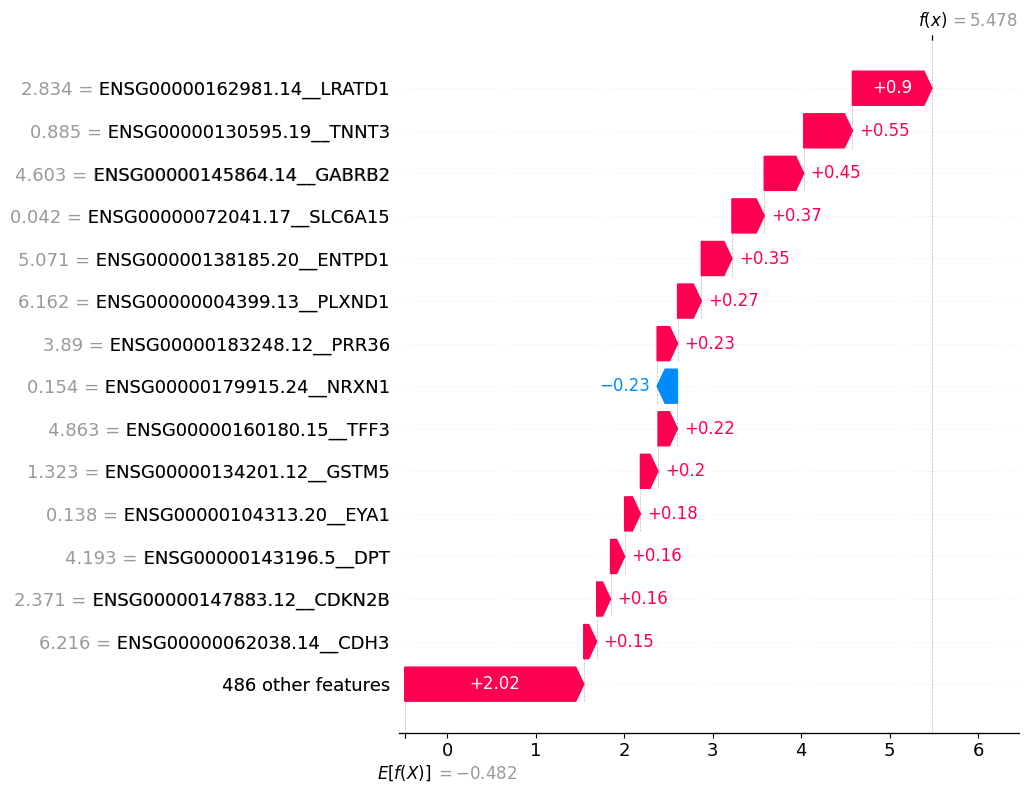

In [24]:

# ==========================================
# CELL 19: INDIVIDUAL SHAP EXPLANATION
# ==========================================

individual_index = 0

individual_explanation = (
    shap_explanation[individual_index]
)

# For binary classification with two output classes,
# select the tumor-class explanation.
if len(individual_explanation.shape) == 2:
    individual_explanation = (
        individual_explanation[:, 1]
    )

shap.plots.waterfall(
    individual_explanation,
    max_display=15,
    show=False
)

plt.savefig(
    RESULTS_DIR / "07_SHAP_Waterfall_Plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [25]:

# ==========================================
# CELL 20: SAVE RESEARCH OUTPUTS
# ==========================================

# Save SHAP values
pd.DataFrame(
    shap_values,
    columns=selected_gene_names
).to_csv(
    RESULTS_DIR / "SHAP_Values.csv",
    index=False
)

# Save selected genes
pd.DataFrame({
    "Selected_Gene": selected_gene_names
}).to_csv(
    RESULTS_DIR / "Selected_500_Genes.csv",
    index=False
)

# Save fitted fold model
joblib.dump(
    shap_model,
    RESULTS_DIR / "SHAP_Explained_Fold1_Model.joblib"
)

print("All research outputs saved!")

print("\nResults directory:")
print(RESULTS_DIR)


All research outputs saved!

Results directory:
/content/drive/MyDrive/datasets/TCGA_THCA_Research_Results
